# Demo: predict Thai patches with ResNet-18 + AdaBN

ResNet-18 trained on EuroSAT only (seed 42). AdaBN re-estimates the BatchNorm statistics on **unlabelled** Thai patches; no weight changes and no label is used.
The scored patches (3,023 pure patches, WorldCover labels) never enter AdaBN.

**Mode used for the video: saved predictions.** The model is not run here; the notebook reads the predictions that `src/predict.py` saved for this exact run (seed 42), so the numbers match the slides. The code in the third code cell is what produced them (set `USE_SAVED = False` in the second code cell to run it).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import config as c
import b_data as d

x_l1c, table = d.load_thai("L1C")            # Thai L1C patches (memory-mapped) and their table
pure = table["pure"].to_numpy()
unlabeled = np.flatnonzero(~pure)             # used only by AdaBN, never scored
print(f"{len(table):,} Thai patches: {pure.sum():,} pure (test set), {len(unlabeled):,} not pure (AdaBN statistics only)")

9,216 Thai patches: 3,023 pure (test set), 6,193 not pure (AdaBN statistics only)


In [2]:
# Which mode? True: read the predictions saved by src/predict.py (the run behind the slides, seed 42).
# False: run the model here (needs torch, timm and data/models/resnet18_12band.pt; the numbers then differ a little).
USE_SAVED = True

CKPT = d.MODEL_DIR / "resnet18_12band.pt"
HAVE_MODEL = False
if not USE_SAVED:
    try:
        import torch
        import predict, train_resnet as tr
        HAVE_MODEL = CKPT.exists()
    except ImportError:
        HAVE_MODEL = False
if HAVE_MODEL:
    print("checkpoint found: running the model")
elif USE_SAVED:
    print("reading the saved predictions (outputs/predictions/, written by src/predict.py): the model does not run in this demo")
else:
    print("no checkpoint or torch on this machine: reading the saved predictions instead")

reading the saved predictions (outputs/predictions/, written by src/predict.py): the model does not run in this demo


In [3]:
if HAVE_MODEL:
    device = tr.pick_device()
    model, ck = predict.load_checkpoint("resnet18_12band", device)                      # 1. trained on EuroSAT only
    mean, std = predict.tensor(ck["mean"], device), predict.tensor(ck["std"], device)
    x = np.asarray(x_l1c)
    predict.adapt_batchnorm(model, x[unlabeled], mean, std, device)                      # 2. AdaBN, no labels
    proba = tr.predict_proba(model, x, mean, std, device)                                # 3. predict every patch
    pred = pd.DataFrame({"patch_id": table["patch_id"],
                         "predicted_label": np.array(c.CLASSES)[proba.argmax(1)],
                         "confidence": proba.max(1)})
else:
    pred = pd.read_csv(d.PRED_DIR / "predictions_resnet18_12band_thai-L1C_adabn.csv")
print(pred.head(3).to_string(index=False))

 patch_id predicted_label  confidence  p_forest  p_crop  p_grassland  p_built-up  p_water
        0        built-up      0.9549       0.0  0.0450          0.0      0.9549   0.0001
        1        built-up      1.0000       0.0  0.0000          0.0      1.0000   0.0000
        2           water      0.9985       0.0  0.0014          0.0      0.0000   0.9985


## Scores on the 3,023 pure patches

In [4]:
res = table.merge(pred, on="patch_id")
test = res[res["pure"]]
right = test["predicted_label"] == test["label"]
macro = f1_score(test["label"], test["predicted_label"], labels=c.THAI_EVAL_CLASSES, average="macro", zero_division=0)
grass = (test["predicted_label"] == "grassland").mean()
print(f"right {right.sum():,}   wrong {(~right).sum():,}")
print(f"accuracy {accuracy_score(test['label'], test['predicted_label']):.3f}   macro-F1 (4 classes) {macro:.3f}   predicted grassland {100 * grass:.1f}%")
print()
print("rows: true label (WorldCover), columns: model answer")
pd.crosstab(test["label"], test["predicted_label"]).reindex(index=c.THAI_EVAL_CLASSES, columns=c.CLASSES, fill_value=0)

right 2,378   wrong 645
accuracy 0.787   macro-F1 (4 classes) 0.897   predicted grassland 18.0%

rows: true label (WorldCover), columns: model answer


predicted_label,forest,crop,grassland,built-up,water
label,,,,,
forest,1267,10,484,1,14
crop,32,408,59,14,22
built-up,0,0,0,272,9
water,0,0,0,0,431


## Patches the model got right and wrong
Top row: one right patch per class. Bottom row: forest predicted as grassland, the main mistake. True colour (B4, B3, B2); the same random draw every run (seed 42).

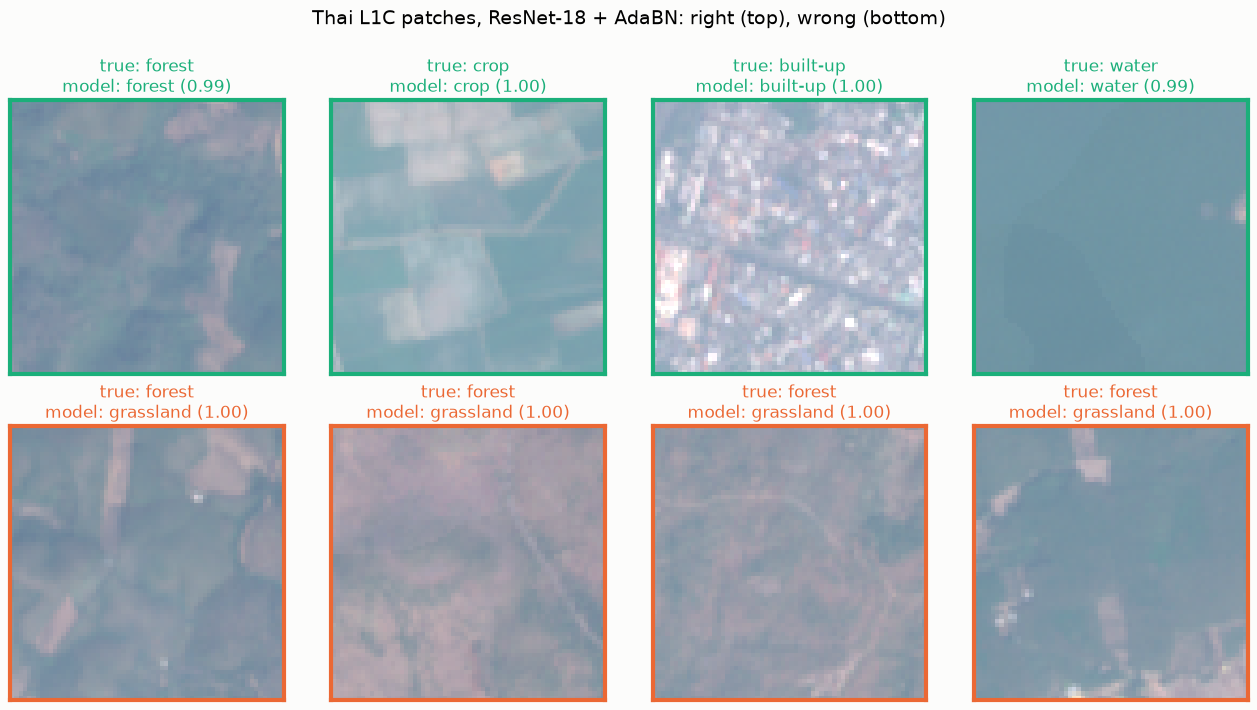

In [5]:
rng = np.random.default_rng(c.SEED)
ok, bad = test[right], test[~right]
good_ids = [rng.choice(ok[ok["label"] == k].index) for k in c.THAI_EVAL_CLASSES]
wrong_ids = rng.choice(bad[(bad["label"] == "forest") & (bad["predicted_label"] == "grassland")].index, 4, replace=False)

iR, iG, iB = (c.BANDS.index(b) for b in ("B4", "B3", "B2"))
def rgb(pid):
    a = np.asarray(x_l1c[pid], dtype="float32")
    return np.clip(np.stack([a[iR], a[iG], a[iB]], -1) / 2200.0, 0, 1) ** (1 / 1.6)

fig, axs = plt.subplots(2, 4, figsize=(13, 7.2), facecolor="#fcfcfb")
for row, (ids, color) in enumerate(((good_ids, "#1baf7a"), (wrong_ids, "#eb6834"))):
    for ax, i in zip(axs[row], ids):
        r = res.loc[i]
        ax.imshow(rgb(int(r["patch_id"])), interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_edgecolor(color); s.set_linewidth(3)
        ax.set_title(f"true: {r['label']}\nmodel: {r['predicted_label']} ({r['confidence']:.2f})", fontsize=12, color=color)
fig.suptitle("Thai L1C patches, ResNet-18 + AdaBN: right (top), wrong (bottom)", fontsize=14)
fig.tight_layout(h_pad=3.0, rect=(0, 0, 1, 0.96))
plt.show()

Notes: one trained model (seed 42), pure patches only; the mean over three seeds is in `outputs/b/b9_seeds.md`.
The patches are drawn at random, so they illustrate the mistake and are not a measure of how common each case is (see the table above).